In [35]:
import numpy as np
import scipy.linalg as la
from scipy.linalg import eig, qr, block_diag
from numpy.linalg import svd
from scipy.linalg import null_space
import math
import matplotlib.pyplot as plt
from numpy.linalg import qr, norm
from scipy.linalg import solve_discrete_are, solve_discrete_lyapunov, block_diag
import random


def grad_true(Sigma_0,A,B,Q,R,K):
    dx = A.shape[0]
    PK = solve_discrete_lyapunov((A-B@K).T,Q+K.T@R@K)
    EK = (R + B.T@PK@B)@K - B.T@PK@A
    Sigma_K = solve_discrete_lyapunov(A-B@K,Sigma_0)
    grad = 2*EK@Sigma_K
    return grad


def grad_avg_true(As,Bs,Qs,Rs,K,Sigma_0,gamma_h):
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    H = len(As)
    grad_avg = np.zeros((du,dx))
    for i in range(H):
        grad_cost_i = grad_true(Sigma_0,np.sqrt(gamma_h[i])*As[i],np.sqrt(gamma_h[i])*Bs[i],Qs[i],Rs[i],K)
        grad_avg += (1/H)*grad_cost_i
    return grad_avg


def zo2p(A, B, Q, R, K, r, ns, gamma):
    dx = A.shape[0]
    du = B.shape[1]
    K1 = []
    K2 = []
    cost_1 = []
    cost_2 = []
    grad = np.zeros((du, dx))
    Ul=[]
    for l in range(ns):
        U = np.random.randn(B.shape[1], A.shape[0])
        U = (U / np.linalg.norm(U))

        K1.append(K + r*U)
        K2.append(K - r*U)

        # Compute cost
        x_0 = np.random.normal(0, 1, size=(1,dx))[0]   
        cost_1.append(cost_gamma_x0(A, B, Q, R, K1[-1],gamma,x_0))
        cost_2.append(cost_gamma_x0(A, B, Q, R, K2[-1],gamma,x_0))
        Ul.append(U)

        #grad += ((dx * du) / (2 * ns * (r))) * (cost_1[l] - cost_2[l]) * Ul[l]
        grad += ((dx * du) / ( ns * (r**2))) * (cost_1[l]) * Ul[l] #one point estimation


    return grad


def cost_gamma(A, B, Q, R, K, gamma, ns_cost):
        dx = A.shape[0]
        tau = 50
        cost = 0
        rng = np.random.default_rng()
        for i in range(ns_cost):
            cost_i = 0
            x = np.random.normal(0, 1, size=(1,dx))[0]
            for t in range(tau):
                u = -K@x
                cost_i += (gamma**t)*(x.T@Q@x + u.T@R@u)
                w = rng.normal(loc=0.0, scale=0.01, size=dx)
                x = (A - B @ K) @ x + w
            cost+=(1/ns_cost)*cost_i  
        
        return cost
    
def cost_gamma_avg(As, Bs, Qs, Rs, K, gamma, ns_cost):
    
    cost_avg = 0
    H = len(As)
    for h in range(H):
        cost_avg+=(1/H)*cost_gamma(As[h], Bs[h], Qs[h], Rs[h], K, gamma, ns_cost)
    
    return cost_avg


def cost_gamma_x0(A, B, Q, R, K, gamma, x):
        dx = A.shape[0]
        rng = np.random.default_rng()
        tau = 50
        cost = 0
        for t in range(tau):
            u = -K@x
            cost += (gamma**t)*(x.T@Q@x + u.T@R@u)
            w = rng.normal(loc=0.0, scale=0.01, size=dx)
            x = (A - B @ K) @ x + w
        return cost

    
def lqr_cost_K(Sigma_0,A,B,Q,R,K,gamma):
        PK = solve_discrete_lyapunov(np.sqrt(gamma)*(A-B@K).T,Q+K.T@R@K)
        return np.trace(Sigma_0@PK)
    
    
def lqr_cost_avg_K(Sigma_0,As,Bs,Qs,Rs,K,gamma):
        cost_avg = 0
        H = len(As)
        for h in range(H):
            cost_avg+=(1/H)*lqr_cost_K(Sigma_0,As[h],Bs[h],Qs[h],Rs[h],K,gamma)
        return cost_avg
    
def gradient_avg_zo2p(As, Bs, Qs, Rs, K, r, ns, gamma_h):
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    H = len(As)
    grad_avg = np.zeros((du,dx))
    
    for h in range(H):
        grad_avg += (1/H)*zo2p(As[h], Bs[h], Qs[h], Rs[h], K, r, ns, gamma_h[h])
    
    return grad_avg


def spectral_radius_mt(As,Bs,K):
    
    H = len(As)
    srs = []
    for h in range(H):
        srs.append(max(abs(la.eigvals(As[h]-Bs[h]@K))))
    
    return srs


def spectral_radius_mt_gamma(As,Bs,K,gamma):
    
    H = len(As)
    srs = []
    for h in range(H):
        srs.append(max(abs(la.eigvals(np.sqrt(gamma)*As[h]-np.sqrt(gamma)*Bs[h]@K))))
    
    return srs



def state_norm(As, Bs, K, tau, gamma, x_bound, x0=None):

    dx = As[0].shape[0]
    flag = 1
    if x0 is None:
        x0 = np.random.randn(dx)
        x0 = x0 / np.linalg.norm(x0)
    H = len(As)
    for h in range(H):    
        
        F = np.sqrt(gamma)*(As[h] - Bs[h] @ K)

        F_tau = np.linalg.matrix_power(F, tau)

        x_tau = F_tau @ x0
        
        if np.linalg.norm(x_tau) >= x_bound:
            flag = 0
            break
    return flag


    
def find_stabilizing_hd(As,Bs,Qs,Rs,gamma,N,r,ns,eta,xi,ns_cost):
    
    H = len(As)
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    K = np.zeros((du,dx))
    sr = []
    Sigma_0 = np.eye(dx)
    
    gammas = []
    
    gamma_h = [gamma]*H
    
    sr.append(spectral_radius_mt(As,Bs,K))
    flag = 0
    
    Ks = [K.copy()]
    check_lyap = 1
    j=0
    error_grads_norm = []
    while flag == 0:
        
        
        gammas.append(gamma_h.copy())
        
        print(f"Iteration: {j}, Spectral radius: {sr[-1][0]}, gamma: {min(gammas[-1])}")
        K_l = K
        error_grads_norm.append(la.norm(gradient_avg_zo2p(As, Bs, Qs, Rs, K.copy(), r, ns, gamma_h) - grad_avg_true(As,Bs,Qs,Rs,K_l,Sigma_0,gamma_h)))
        print(error_grads_norm[-1])
        for n in range(N):
            grad_avg = gradient_avg_zo2p(As, Bs, Qs, Rs, K_l, r, ns, gamma_h)
            K_l=K_l - eta*grad_avg
        K = K_l
        
        print("-----")
        print(f"cost: {lqr_cost_K(Sigma_0,As[0],Bs[0],Qs[0],Rs[0],K,gamma_h[0])}")
        print("-----")
       
        
        #Update the discount factor
        alphas = []
        for h in range(H):
            sigma_min_h = min(abs(la.eigvals(Qs[h] + K.T@Rs[h]@K)))
            alpha_h = sigma_min_h/(2*cost_gamma(As[h], Bs[h], Qs[h], Rs[h], K, gamma_h[h],ns_cost) - sigma_min_h)
            #alpha_h = sigma_min_h/(2*lqr_cost_K(Sigma_0,As[h],Bs[h],Qs[h],Rs[h],K,gamma_h[h]) - sigma_min_h)
            alphas.append(alpha_h)
            
           
        print("-----")
        print(f"min alpha ={min(alphas)}, avg alpha = {np.mean(alphas)}")
        print("-----")
        
         
        
        gamma_h_min = [(1+xi*min(alphas))*gamma_h[0]]*H
        gamma_h = gamma_h_min.copy()
        
    
        Ks.append(K.copy)
        sr.append(spectral_radius_mt(As,Bs,K))  
        
        if gamma_h[0]>=1: 
            flag = 1
            gammas.append(gamma_h.copy())
            break
        
        j+=1
        
    return K, sr, gammas, Ks, error_grads_norm


def is_positive_definite_eig(A, tol=1e-8):
    if not np.allclose(A, A.T):
        print("Warning: Matrix is not symmetric. Eigenvalue test alone is not sufficient.")
        return False
        
    eigenvalues = np.linalg.eigvalsh(A)
    
    # Check if all eigenvalues are greater than a small tolerance
    return np.all(eigenvalues > tol)


def verify_gamma(K,As,Bs,Qs,Rs,gamma,gamma_plus):
    
    flag = 1
    for h in range(len(As)):
        PK_h = solve_discrete_lyapunov(np.sqrt(gamma)*(As[h]-Bs[h]@K).T,Qs[h]+K.T@Rs[h]@K)
        
        M = PK_h - (gamma_plus/gamma)*(PK_h - (Qs[h]+K.T@Rs[h]@K)) 
        
        if is_positive_definite_eig(M) == False:
            flag = 0
    
    return flag




def update_gamma(gamma, As, Bs, Qs, Rs, K, Sigma_0):
        C_old = lqr_cost_avg_K(Sigma_0,As,Bs,Qs,Rs,K,gamma)
        gamma_lb = gamma
        gamma_ub = 1.0
        
        # bisection
        while gamma_ub - gamma_lb > 1e-4:
            gamma_mid = (gamma_ub + gamma_lb)/2
            C_new = lqr_cost_avg_K(Sigma_0,As,Bs,Qs,Rs,K,gamma_mid)

            if C_new < 2.5*C_old:
                    gamma_lb = gamma_mid
            elif C_new > 4*C_old:
                    gamma_ub = gamma_mid
            else:
                    gamma_lb = gamma_mid
                    break
        print(gamma_lb)
        return gamma_lb

$\textbf{LTI system (Cartpole)}$

In [64]:
l = 3 #number of unstable modes
d0 = 4
du = 1

H = 1000
As = []
Bs = []
Qs = []
Rs = []

dt = 0.25
g = 9.8


for h in range(H):

    mc = 1 + 0.1*np.random.rand()
    mp = 0.5 + 0.1*np.random.rand()
    ell = 0.75 + 0.1*np.random.rand()

    Ac = np.array([[ 0.  ,  1.,    0.  ,       0.  ],
                   [ 0.  ,  0.  , (mp/mc)*g ,  0.  ],
                   [ 0.  ,  0.  ,  0.  ,       1.],
                   [ 0.  ,  0.  ,  g*(mp + mc)/(ell*mc)  ,  0  ]])

    Bc = np.array([[ 0.  ],
                   [ 1/mc],
                   [ 0.  ],
                   [1/(ell*mc)]])


    A0 = np.eye(d0)+dt*Ac
    B0 = dt*Bc
    As.append(A0)
    Bs.append(B0)
    Qs.append(np.eye(d0))
    Rs.append(np.eye(du))

In [65]:
abs(la.eigvals(As[0]))

array([1.        , 1.        , 2.12038881, 0.12038881])

In [66]:
def geometric_multiplicities_outside_unit_circle(A, tol=1e-8, group_tol=1e-6):
    """
    Return the geometric multiplicity of each eigenvalue of A
    with absolute value >= 1.

    Parameters
    ----------
    A : np.ndarray
        Square matrix.
    tol : float
        Tolerance used to determine numerical rank.
    group_tol : float
        Tolerance used to group nearly identical eigenvalues.

    Returns
    -------
    result : list of tuples
        Each tuple is (eigenvalue_representative, geometric_multiplicity).
    """
    A = np.asarray(A)
    n, m = A.shape
    if n != m:
        raise ValueError("A must be square.")

    eigvals = np.linalg.eigvals(A)

    # Keep only eigenvalues with abs(lambda) >= 1
    selected = [lam for lam in eigvals if abs(lam) >= 1 - group_tol]

    # Group numerically close eigenvalues together
    groups = []
    for lam in selected:
        placed = False
        for g in groups:
            if abs(lam - g[0]) < group_tol:
                g.append(lam)
                placed = True
                break
        if not placed:
            groups.append([lam])

    result = []
    I = np.eye(n, dtype=A.dtype)

    for g in groups:
        lam = sum(g) / len(g)  # representative
        M = A - lam * I
        rank = np.linalg.matrix_rank(M, tol=tol)
        gm = n - rank
        result.append((lam, gm))

    return result

geometric_multiplicities_outside_unit_circle(As[0], tol=1e-8, group_tol=1e-6)

[(np.float64(1.0), np.int64(1)), (np.float64(2.120388809843873), np.int64(1))]

$\textbf{Parameters:}$

In [67]:
gamma = 0.2
ns = 10
r = 0.15
N = 10
xi = 0.5
ns_cost = 50

$\textbf{Single Task:}$

In [83]:
eta = 0.1e-7

As_single = [As[0]]
Bs_single = [Bs[0]]
Qs_single = [100*Qs[0]]
Rs_single = [0.1*Rs[0]]
K_single,srs_singletask,gammas_singletask,Ks_single, error_grads_norm = find_stabilizing_hd(As_single,Bs_single,Qs_single,Rs_single,gamma,N,r,ns,eta,xi,ns_cost)

Iteration: 0, Spectral radius: 2.120388809843873, gamma: 0.2
446295.4731814248
-----
cost: 5848.987429935602
-----
-----
min alpha =0.008642501460563383, avg alpha = 0.008642501460563383
-----
Iteration: 1, Spectral radius: 2.1209935730344003, gamma: 0.20086425014605636
563122.6595683885
-----
cost: 6137.389219731693
-----
-----
min alpha =0.009332868296418464, avg alpha = 0.009332868296418464
-----
Iteration: 2, Spectral radius: 2.1217905711991367, gamma: 0.20180156994209236
1326889.3351527038
-----
cost: 6315.625325408484
-----
-----
min alpha =0.009646441274085638, avg alpha = 0.009646441274085638
-----
Iteration: 3, Spectral radius: 2.119863779913883, gamma: 0.2027749034388247
321462.0930288015
-----
cost: 6597.782149796596
-----
-----
min alpha =0.008879201702087617, avg alpha = 0.008879201702087617
-----
Iteration: 4, Spectral radius: 2.119360392153334, gamma: 0.20367514307270204
383901.3661753355
-----
cost: 6749.788495620357
-----
-----
min alpha =0.009097148282534911, avg alph

-----
cost: 10792.992141764402
-----
-----
min alpha =0.00507397086121018, avg alpha = 0.00507397086121018
-----
Iteration: 42, Spectral radius: 2.045659854034499, gamma: 0.22683449981186357
1622917.5176122524
-----
cost: 10600.113791857711
-----
-----
min alpha =0.005971334734273791, avg alpha = 0.005971334734273791
-----
Iteration: 43, Spectral radius: 2.0422147747757746, gamma: 0.22751175217569267
514367.7059063316
-----
cost: 11292.175280858924
-----
-----
min alpha =0.005207665077392473, avg alpha = 0.005207665077392473
-----
Iteration: 44, Spectral radius: 2.04264789115349, gamma: 0.22810415467894354
557632.1589703037
-----
cost: 10787.50326521171
-----
-----
min alpha =0.00560178330852677, avg alpha = 0.00560178330852677
-----
Iteration: 45, Spectral radius: 2.0375614260130095, gamma: 0.22874304970208661
1816280.4742727568
-----
cost: 10712.607927772415
-----
-----
min alpha =0.005117646725922002, avg alpha = 0.005117646725922002
-----
Iteration: 46, Spectral radius: 2.034491520

-----
min alpha =0.004559580993542078, avg alpha = 0.004559580993542078
-----
Iteration: 81, Spectral radius: 1.9554547365576573, gamma: 0.25043698083566307
743443.358237812
-----
cost: 12457.561154007137
-----
-----
min alpha =0.004349672112258858, avg alpha = 0.004349672112258858
-----
Iteration: 82, Spectral radius: 1.9539008270337404, gamma: 0.25098164021137265
1258671.662233125
-----
cost: 11885.681057952654
-----
-----
min alpha =0.0035441598815279425, avg alpha = 0.0035441598815279425
-----
Iteration: 83, Spectral radius: 1.949815306709435, gamma: 0.2514263997414912
439504.2477879571
-----
cost: 11783.252372871051
-----
-----
min alpha =0.005874252612426203, avg alpha = 0.005874252612426203
-----
Iteration: 84, Spectral radius: 1.9478400882000886, gamma: 0.2521648708342484
1708285.1031875557
-----
cost: 11447.683284772751
-----
-----
min alpha =0.00499231272562942, avg alpha = 0.00499231272562942
-----
Iteration: 85, Spectral radius: 1.943685218241552, gamma: 0.25279431378105965

-----
min alpha =0.006142360339333505, avg alpha = 0.006142360339333505
-----
Iteration: 120, Spectral radius: 1.8716193534695755, gamma: 0.27526745048704204
1017835.5584334936
-----
cost: 13695.05471713661
-----
-----
min alpha =0.0037703525619437795, avg alpha = 0.0037703525619437795
-----
Iteration: 121, Spectral radius: 1.8696688471847038, gamma: 0.27578637815562385
668944.0049165167
-----
cost: 13289.947543350108
-----
-----
min alpha =0.0041630581914709796, avg alpha = 0.0041630581914709796
-----
Iteration: 122, Spectral radius: 1.866885356543444, gamma: 0.2763604355259623
457816.84803532175
-----
cost: 14127.639451898847
-----
-----
min alpha =0.0033924881499924273, avg alpha = 0.0033924881499924273
-----
Iteration: 123, Spectral radius: 1.8671485874229905, gamma: 0.2768292102772866
464256.925657692
-----
cost: 13343.94864889903
-----
-----
min alpha =0.0051727661312026595, avg alpha = 0.0051727661312026595
-----
Iteration: 124, Spectral radius: 1.8635422356664082, gamma: 0.2775

-----
min alpha =0.0043785288293173, avg alpha = 0.0043785288293173
-----
Iteration: 159, Spectral radius: 1.802723442807901, gamma: 0.299163562591895
1094419.2518905147
-----
cost: 15985.16004847103
-----
-----
min alpha =0.0037823176244070633, avg alpha = 0.0037823176244070633
-----
Iteration: 160, Spectral radius: 1.7987894870674024, gamma: 0.2997293283995809
3108556.5192625
-----
cost: 15608.902535483734
-----
-----
min alpha =0.003924570683298915, avg alpha = 0.003924570683298915
-----
Iteration: 161, Spectral radius: 1.796363565368244, gamma: 0.3003174828671618
2429137.1545281536
-----
cost: 17117.627071884508
-----
-----
min alpha =0.003602517245131807, avg alpha = 0.003602517245131807
-----
Iteration: 162, Spectral radius: 1.7974024813168485, gamma: 0.3008584323226836
1509967.079544509
-----
cost: 15626.867196642734
-----
-----
min alpha =0.0036725585283449535, avg alpha = 0.0036725585283449535
-----
Iteration: 163, Spectral radius: 1.7931988041924878, gamma: 0.3014108924234092

-----
cost: 13873.612129191457
-----
-----
min alpha =0.006079013823379224, avg alpha = 0.006079013823379224
-----
Iteration: 198, Spectral radius: 1.7231233094333163, gamma: 0.3245299730481372
1992315.6371266693
-----
cost: 13477.815317830138
-----
-----
min alpha =0.004513971082189702, avg alpha = 0.004513971082189702
-----
Iteration: 199, Spectral radius: 1.7193318427870214, gamma: 0.32526243250495873
1356691.7067482208
-----
cost: 14332.482886844598
-----
-----
min alpha =0.004358026240770661, avg alpha = 0.004358026240770661
-----
Iteration: 200, Spectral radius: 1.7196181619283137, gamma: 0.3259711836129555
1206886.4743920313
-----
cost: 12989.160881205287
-----
-----
min alpha =0.005515607709952065, avg alpha = 0.005515607709952065
-----
Iteration: 201, Spectral radius: 1.7137593955557846, gamma: 0.3268701481997344
3620731.5582114425
-----
cost: 13494.722284761761
-----
-----
min alpha =0.004758562720283907, avg alpha = 0.004758562720283907
-----
Iteration: 202, Spectral radius:

... (41 outputs left out)

-----
min alpha =0.0004362119186286542, avg alpha = 0.0004362119186286542
-----
Iteration: 1866, Spectral radius: 1.0041247981021222, gamma: 0.9398117113445552
18331321.620127965
-----
cost: 104126.22209182665
-----
-----
min alpha =0.0005020451278839122, avg alpha = 0.0005020451278839122
-----
Iteration: 1867, Spectral radius: 1.0051331266400159, gamma: 0.9400476252899597
6606027.007259537
-----
cost: 345456.65287099633
-----
-----
min alpha =0.0002090508519967609, avg alpha = 0.0002090508519967609
-----
Iteration: 1868, Spectral radius: 1.0248451439316992, gamma: 0.9401458841684519
16010710.166535432
-----
cost: 76708.83811789058
-----
-----
min alpha =0.0005545624846110727, avg alpha = 0.0005545624846110727
-----
Iteration: 1869, Spectral radius: 0.9919348905731397, gamma: 0.9404065689871626
8595953.572731018
-----
cost: 75439.64172165864
-----
-----
min alpha =0.000592445591131919, avg alpha = 0.000592445591131919
-----
Iteration: 1870, Spectral radius: 0.9901303515903628, gamma: 0

-----
min alpha =0.001163731475133258, avg alpha = 0.001163731475133258
-----
Iteration: 1905, Spectral radius: 0.9278484830700731, gamma: 0.9538929952472631
3027723.3119269786
-----
cost: 66573.51914253976
-----
-----
min alpha =0.0007966973983826721, avg alpha = 0.0007966973983826721
-----
Iteration: 1906, Spectral radius: 0.9344657140819356, gamma: 0.9542729772810876
4100474.4035399114
-----
cost: 68700.4614722468
-----
-----
min alpha =0.0005747526499911592, avg alpha = 0.0005747526499911592
-----
Iteration: 1907, Spectral radius: 0.9415090897430294, gamma: 0.9545472127423412
2920153.3813414993
-----
cost: 75414.59338649137
-----
-----
min alpha =0.000565422312556373, avg alpha = 0.000565422312556373
-----
Iteration: 1908, Spectral radius: 0.9388907706090232, gamma: 0.9548170738885777
17369637.991892025
-----
cost: 124055.1565122403
-----
-----
min alpha =0.0003952153363231729, avg alpha = 0.0003952153363231729
-----
Iteration: 1909, Spectral radius: 0.9904344427414722, gamma: 0.95

-----
cost: 58993.85986285893
-----
-----
min alpha =0.000806963140970282, avg alpha = 0.000806963140970282
-----
Iteration: 1944, Spectral radius: 0.970534238911555, gamma: 0.9707080486406837
4414085.600863813
-----
cost: 60837.745608170364
-----
-----
min alpha =0.0007910209098908468, avg alpha = 0.0007910209098908468
-----
Iteration: 1945, Spectral radius: 0.9706208869447436, gamma: 0.9710919738226207
5612087.992224994
-----
cost: 58072.12438968734
-----
-----
min alpha =0.0010263695531052529, avg alpha = 0.0010263695531052529
-----
Iteration: 1946, Spectral radius: 0.9587724737807409, gamma: 0.971590323440219
8484664.335154513
-----
cost: 56782.189035041025
-----
-----
min alpha =0.0006699257358854184, avg alpha = 0.0006699257358854184
-----
Iteration: 1947, Spectral radius: 0.9466988891736411, gamma: 0.9719157701214239
7932715.104878033
-----
cost: 58776.530972786495
-----
-----
min alpha =0.0007314650221029222, avg alpha = 0.0007314650221029222
-----
Iteration: 1948, Spectral rad

-----
cost: 61764.452600392426
-----
-----
min alpha =0.0008262740086314239, avg alpha = 0.0008262740086314239
-----
Iteration: 1983, Spectral radius: 0.9012058299564112, gamma: 0.9873699842464935
4797969.986596519
-----
cost: 59818.21474807966
-----
-----
min alpha =0.0007980150825179544, avg alpha = 0.0007980150825179544
-----
Iteration: 1984, Spectral radius: 0.8900826698418824, gamma: 0.9877639523162206
9822468.783157272
-----
cost: 55763.18171740579
-----
-----
min alpha =0.0008736869043036151, avg alpha = 0.0008736869043036151
-----
Iteration: 1985, Spectral radius: 0.8733205337001257, gamma: 0.9881954505310615
3539125.61008257
-----
cost: 52566.884772566154
-----
-----
min alpha =0.0007341656049631447, avg alpha = 0.0007341656049631447
-----
Iteration: 1986, Spectral radius: 0.8623443458914347, gamma: 0.9885582000864419
4500290.409945685
-----
cost: 53319.98565997996
-----
-----
min alpha =0.001233506947724519, avg alpha = 0.001233506947724519
-----
Iteration: 1987, Spectral rad

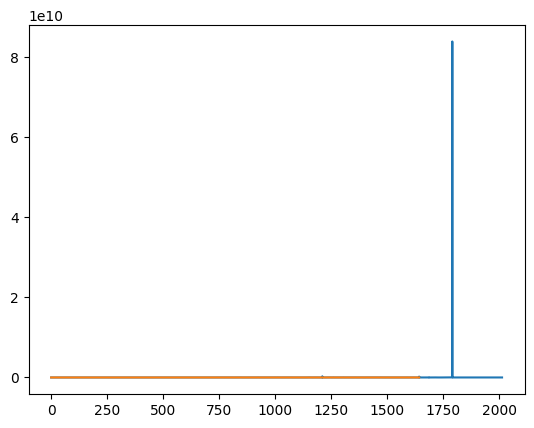

In [84]:
plt.plot(error_grads_norm)
plt.plot(error_grads_norm4)

$\textbf{Multitask:}$

$H=10$

In [73]:
eta = 0.5e-7
H_tasks = 10

indices = random.sample(range(1, H), H_tasks-1)

As_tasks = [As[0]]
Bs_tasks = [Bs[0]]
Qs_tasks = [100*Qs[0]]
Rs_tasks = [0.1*Rs[0]]
for h in range(len(indices)):
    As_tasks.append(As[indices[h]])
    Bs_tasks.append(Bs[indices[h]])
    Qs_tasks.append(100*Qs[indices[h]])
    Rs_tasks.append(0.1*Rs[indices[h]])

K_H25,srs_multitask_H25,gammas_multitask_H25, Ks_H25, error_grads_norm4 = find_stabilizing_hd(As_tasks,Bs_tasks,Qs_tasks,Rs_tasks,gamma,N,r,ns,eta,xi, ns_cost)

Iteration: 0, Spectral radius: 2.120388809843873, gamma: 0.2
132655.31094434965
-----
cost: 5757.897423540851
-----
-----
min alpha =0.005870392205740476, avg alpha = 0.012199432868193433
-----
Iteration: 1, Spectral radius: 2.1191808764699487, gamma: 0.20058703922057408
187153.55609929602
-----
cost: 5765.986928154971
-----
-----
min alpha =0.0074989643037705125, avg alpha = 0.011925581326139061
-----
Iteration: 2, Spectral radius: 2.1162909170044983, gamma: 0.20133913674403114
132494.3355765338
-----
cost: 5905.862263757286
-----
-----
min alpha =0.007868009843027001, avg alpha = 0.012288608585201992
-----
Iteration: 3, Spectral radius: 2.1152125843620406, gamma: 0.20213120589887545
188678.577704472
-----
cost: 6080.703513935603
-----
-----
min alpha =0.007188710772431496, avg alpha = 0.010031554299701134
-----
Iteration: 4, Spectral radius: 2.114332241149799, gamma: 0.20285773728752035
135722.04175782355
-----
cost: 5853.853841798246
-----
-----
min alpha =0.007926655581228285, avg 

-----
cost: 6102.647217122033
-----
-----
min alpha =0.007823866933426784, avg alpha = 0.010155053928743538
-----
Iteration: 40, Spectral radius: 1.9900587612718883, gamma: 0.23045944868933857
145841.19623052055
-----
cost: 6307.972973480035
-----
-----
min alpha =0.006683334274200907, avg alpha = 0.01038502648423303
-----
Iteration: 41, Spectral radius: 1.989456454419074, gamma: 0.23122956745545803
117261.48593572898
-----
cost: 6178.9692732737385
-----
-----
min alpha =0.006785393636148702, avg alpha = 0.009435466715151372
-----
Iteration: 42, Spectral radius: 1.9844719558330701, gamma: 0.2320140592732089
129915.67753509842
-----
cost: 6024.560443759049
-----
-----
min alpha =0.006981611370262065, avg alpha = 0.01046807323111861
-----
Iteration: 43, Spectral radius: 1.9789609375471215, gamma: 0.23282397527035015
315075.12479263166
-----
cost: 6063.32345025426
-----
-----
min alpha =0.007913228835636617, avg alpha = 0.011235066929473337
-----
Iteration: 44, Spectral radius: 1.97627491

-----
cost: 7232.228643842687
-----
-----
min alpha =0.005625849067023843, avg alpha = 0.008723070476982798
-----
Iteration: 79, Spectral radius: 1.8803215012932304, gamma: 0.2632802748486691
136238.08238464032
-----
cost: 6838.823330274739
-----
-----
min alpha =0.006497475712148579, avg alpha = 0.00944475236280594
-----
Iteration: 80, Spectral radius: 1.8736746608118573, gamma: 0.2641356034443276
215793.0514863732
-----
cost: 6819.331913443375
-----
-----
min alpha =0.006441046642867331, avg alpha = 0.010234713262622886
-----
Iteration: 81, Spectral radius: 1.8705827685442882, gamma: 0.2649862583152411
142837.08492590525
-----
cost: 7032.306237741099
-----
-----
min alpha =0.005890883141010664, avg alpha = 0.009445898726638539
-----
Iteration: 82, Spectral radius: 1.8699656448103037, gamma: 0.26576675985609544
254972.77176425947
-----
cost: 7140.814273164696
-----
-----
min alpha =0.00603575730683974, avg alpha = 0.008857200769768231
-----
Iteration: 83, Spectral radius: 1.8683827330

-----
cost: 7083.5195558688365
-----
-----
min alpha =0.006329423272060972, avg alpha = 0.008835365343937931
-----
Iteration: 118, Spectral radius: 1.7680702711337801, gamma: 0.29779570531414806
102166.52483528983
-----
cost: 7424.811210937544
-----
-----
min alpha =0.005698560933320386, avg alpha = 0.009316798545640366
-----
Iteration: 119, Spectral radius: 1.7687222402000526, gamma: 0.29864420880035497
122123.43933641969
-----
cost: 7326.129097196196
-----
-----
min alpha =0.008178333439306318, avg alpha = 0.010508266416970136
-----
Iteration: 120, Spectral radius: 1.7653705467352836, gamma: 0.29986541475999856
118822.43225113879
-----
cost: 7504.9565068066695
-----
-----
min alpha =0.005750113717752063, avg alpha = 0.010219107187761887
-----
Iteration: 121, Spectral radius: 1.7633366443299112, gamma: 0.300727544877444
235585.3268645565
-----
cost: 7367.495542390683
-----
-----
min alpha =0.004924680663936592, avg alpha = 0.00813423525431668
-----
Iteration: 122, Spectral radius: 1.7

-----
cost: 7499.360373095565
-----
-----
min alpha =0.005716019803348932, avg alpha = 0.007890950852418758
-----
Iteration: 157, Spectral radius: 1.663983248624741, gamma: 0.3343520656731601
289360.2191393955
-----
cost: 7614.988589214253
-----
-----
min alpha =0.004518876403787576, avg alpha = 0.008411195753143821
-----
Iteration: 158, Spectral radius: 1.662018172670303, gamma: 0.3351075135032242
335602.350232758
-----
cost: 7548.155774035716
-----
-----
min alpha =0.00653894260651549, avg alpha = 0.008553939058039268
-----
Iteration: 159, Spectral radius: 1.6592009336281337, gamma: 0.336203137902129
282931.94010814145
-----
cost: 7354.42662302451
-----
-----
min alpha =0.005749821591744501, avg alpha = 0.00758610294317875
-----
Iteration: 160, Spectral radius: 1.6534333901934732, gamma: 0.33716969193289
300607.1761749855
-----
cost: 7202.64453235149
-----
-----
min alpha =0.005744939160062613, avg alpha = 0.008528486417976572
-----
Iteration: 161, Spectral radius: 1.6484452819514346

-----
cost: 7619.96020827903
-----
-----
min alpha =0.0063744504095926725, avg alpha = 0.008407021447763195
-----
Iteration: 196, Spectral radius: 1.5401290691612546, gamma: 0.3718382463154053
214660.75428140283
-----
cost: 7754.46811100194
-----
-----
min alpha =0.004957625770567035, avg alpha = 0.007904120413784372
-----
Iteration: 197, Spectral radius: 1.5367258171578022, gamma: 0.37275996375161313
262728.9877575061
-----
cost: 7847.7826439619785
-----
-----
min alpha =0.005309919198856632, avg alpha = 0.00807894744109872
-----
Iteration: 198, Spectral radius: 1.5360083565549356, gamma: 0.373749626395658
315801.46498069837
-----
cost: 7861.532030089777
-----
-----
min alpha =0.005525233462399678, avg alpha = 0.007004262049353718
-----
Iteration: 199, Spectral radius: 1.5302090559844428, gamma: 0.37478215336681836
138004.87941660895
-----
cost: 7939.950378879518
-----
-----
min alpha =0.006206072609627118, avg alpha = 0.0071265099528735635
-----
Iteration: 200, Spectral radius: 1.526

... (33 outputs left out)

-----
cost: 34233.65906978636
-----
-----
min alpha =0.0010337522190714762, avg alpha = 0.0016322857205941087
-----
Iteration: 1522, Spectral radius: 0.8758074240298421, gamma: 0.9470114900746209
1294866.6383914314
-----
cost: 34704.97352841394
-----
-----
min alpha =0.001106198402977092, avg alpha = 0.0014387831281885283
-----
Iteration: 1523, Spectral radius: 0.8933816514504198, gamma: 0.9475352813735818
1197957.3075089415
-----
cost: 36633.559109710426
-----
-----
min alpha =0.0010555128662864692, avg alpha = 0.0013874289740045344
-----
Iteration: 1524, Spectral radius: 0.9204699224153216, gamma: 0.9480353492139568
790090.8875664946
-----
cost: 38638.02401465448
-----
-----
min alpha =0.0008292126159925178, avg alpha = 0.0013338231574116315
-----
Iteration: 1525, Spectral radius: 0.9226174623131551, gamma: 0.9484284106499443
631735.2272880236
-----
cost: 34197.857882881726
-----
-----
min alpha =0.001239754546929523, avg alpha = 0.0016638722106652713
-----
Iteration: 1526, Spectral 

-----
cost: 40207.78214320785
-----
-----
min alpha =0.0009076676263954153, avg alpha = 0.0012411960910442947
-----
Iteration: 1561, Spectral radius: 0.8698966137287321, gamma: 0.9647446636600222
2338514.6697553433
-----
cost: 38020.62352583763
-----
-----
min alpha =0.0011229062087473505, avg alpha = 0.001499920272193852
-----
Iteration: 1562, Spectral radius: 0.7726593220548547, gamma: 0.965286322546362
575065.3237883061
-----
cost: 39888.174922697486
-----
-----
min alpha =0.0008372922814086945, avg alpha = 0.0012305199496931603
-----
Iteration: 1563, Spectral radius: 0.8149572868287593, gamma: 0.9656904359399707
352611.56604098907
-----
cost: 39512.76267046785
-----
-----
min alpha =0.0008313353568815215, avg alpha = 0.0011420481545295963
-----
Iteration: 1564, Spectral radius: 0.8615302512281638, gamma: 0.9660918422415704
1234963.4893860433
-----
cost: 41422.87440850016
-----
-----
min alpha =0.0009190776950918531, avg alpha = 0.0012515836712166488
-----
Iteration: 1565, Spectral 

-----
cost: 37752.362968429516
-----
-----
min alpha =0.000880936060609401, avg alpha = 0.0013541771453601263
-----
Iteration: 1600, Spectral radius: 0.8968333923822916, gamma: 0.9811558865034381
1303937.0268859735
-----
cost: 37767.03438342793
-----
-----
min alpha =0.0007640117661004921, avg alpha = 0.0012235621860595689
-----
Iteration: 1601, Spectral radius: 0.8931509770659444, gamma: 0.9815306938242717
1075582.2795389008
-----
cost: 39953.89525958358
-----
-----
min alpha =0.0008886056760055087, avg alpha = 0.0012176228840753828
-----
Iteration: 1602, Spectral radius: 0.8666614741066425, gamma: 0.9819667906971247
866560.1685483411
-----
cost: 38844.453117830584
-----
-----
min alpha =0.0006444519950256006, avg alpha = 0.0011850288849838393
-----
Iteration: 1603, Spectral radius: 0.9062759941979049, gamma: 0.9822832059257816
1231931.2066779989
-----
cost: 37592.45245083292
-----
-----
min alpha =0.0010606526649942596, avg alpha = 0.0014681026463099721
-----
Iteration: 1604, Spectra

-----
cost: 39807.02920163976
-----
-----
min alpha =0.0009190689306249552, avg alpha = 0.0013174989393342684
-----
Iteration: 1639, Spectral radius: 0.8689275576045018, gamma: 0.9985939469193253
1066163.7862105514
-----
cost: 40212.23739357403
-----
-----
min alpha =0.0008453496641893943, avg alpha = 0.0012537908423653013
-----
Iteration: 1640, Spectral radius: 0.8566915156610208, gamma: 0.9990160274481703
1626078.0382297048
-----
cost: 39860.76030498431
-----
-----
min alpha =0.0008557953422770637, avg alpha = 0.001221564207010669
-----
Iteration: 1641, Spectral radius: 0.8677515943336136, gamma: 0.9994435040797454
1873179.055193024
-----
cost: 43063.18920930019
-----
-----
min alpha =0.000812523796655439, avg alpha = 0.0011854346593040722
-----
Iteration: 1642, Spectral radius: 0.9108703784313276, gamma: 0.9998495398949842
1626708.0664447367
-----
cost: 39980.145725272
-----
-----
min alpha =0.0008907219134013747, avg alpha = 0.0011376904110786184
-----


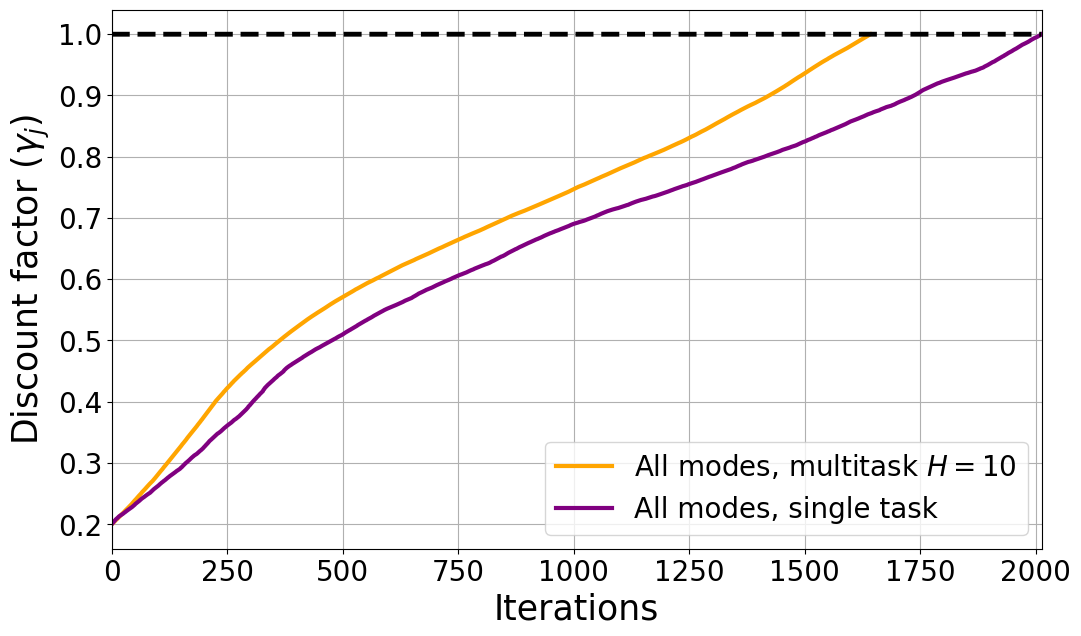

In [85]:
gamma_multitask_H25 = []

for i in range(len(gammas_multitask_H25)):
    if gammas_multitask_H25[i][0]<=1:
        gamma_multitask_H25.append(gammas_multitask_H25[i][0])
        

gamma_singletask = []

for i in range(len(gammas_singletask)):
    if gammas_singletask[i][0] <= 1:
        gamma_singletask.append(gammas_singletask[i][0])

plt.figure(figsize=(12,7))
plt.plot(gamma_multitask_H25, color='orange', label=r'All modes, multitask $H = 10$', linewidth=3)
plt.plot(gamma_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(gamma_singletask)), np.ones(len(gamma_singletask)), linestyle='--', color='black', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylabel(r'Discount factor $(\gamma_j)$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()

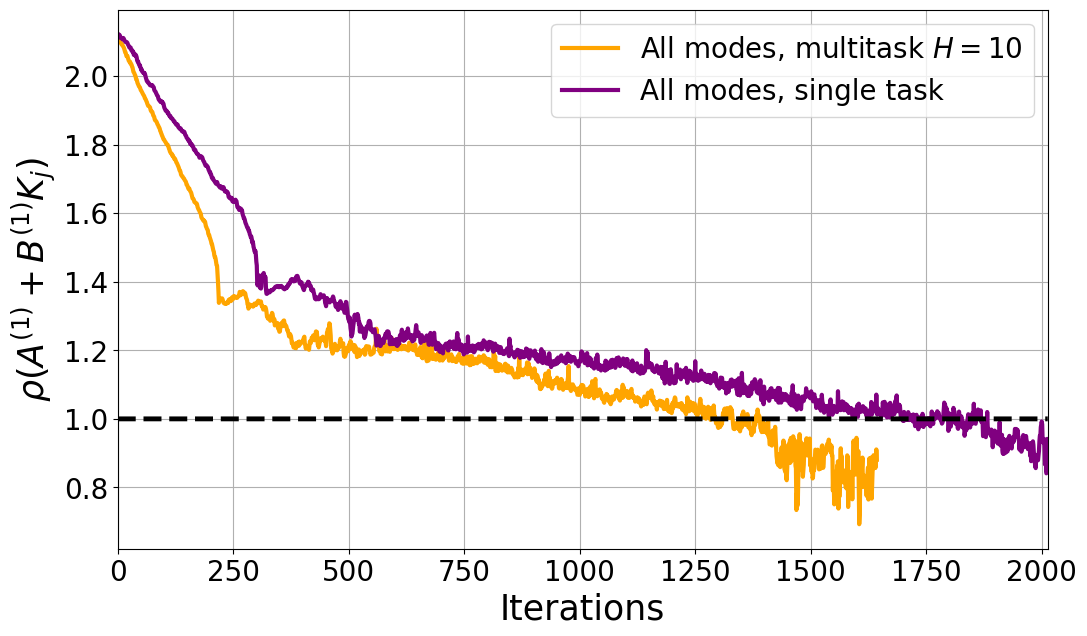

In [88]:
idx = 0

sr_multitask_H25 = []

for i in range(len(srs_multitask_H25)):
    sr_multitask_H25.append(srs_multitask_H25[i][idx])
    
    
sr_singletask = []

for i in range(len(srs_singletask)):
    sr_singletask.append(srs_singletask[i][0])


plt.figure(figsize=(12,7))
plt.plot(sr_multitask_H25, color='orange', label=r'All modes, multitask $H = 10$', linewidth=3)
plt.plot(sr_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(sr_singletask)), np.ones(len(sr_singletask)), linestyle='--', color='black', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylabel(r'$\rho(A^{(1)}+B^{(1)}K_{j})$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()

$\textbf{Learning on a shared subspace:}$

In [89]:
def find_stabilizing_ld(As,Bs,Qs,Rs,gamma,N,r,ns,eta,xi,ns_cost,Phi, As_original, Bs_original):
    
    H = len(As)
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    K = np.zeros((du,dx))
    sr = []
    Sigma_0 = np.eye(dx)
    
    
    gammas = []
    k = 0
    
    gamma_h = [gamma]*H
    sr.append(spectral_radius_mt(As_original,Bs_original,K@Phi.T))
    flag = 0
    
    Ks = [K.copy()]
    while flag == 0:
        
        
        gammas.append(gamma_h.copy())
        
        print(f"Iteration: {k}, Spectral radius: {max(sr[-1])}, gamma: {min(gammas[-1])}")
        K_l = K
        for n in range(N):
            grad_avg = gradient_avg_zo2p(As, Bs, Qs, Rs, K_l, r, ns, gamma_h)
            K_l=K_l - eta*grad_avg
        K = K_l
        
        
        #Update the discount factor
        alphas = []
        gammas_copy = gamma_h.copy()
        gammas_h = gamma_h.copy()
        for h in range(H):
            sigma_min_h = min(abs(la.eigvals(Qs[h] + K.T@Rs[h]@K)))
            alpha_h = sigma_min_h/(2*cost_gamma(As[h], Bs[h], Qs[h], Rs[h], K, gamma_h[h],ns_cost) - sigma_min_h)
            gammas_h[h] = (1+alpha_h*xi)*gammas_h[h]
            alphas.append(alpha_h)
            

        print("-----")
        print(f"min alpha = {min(alphas)}, avg alpha = {np.mean(alphas)}")
        print("-----")
           
            
        gamma_h_min = [(1+xi*min(alphas))*gamma_h[0]]*H
        gamma_h = gamma_h_min.copy()     
    
    
        Ks.append(K.copy)
        sr.append(spectral_radius_mt(As_original,Bs_original,K@Phi.T))  
        
        if min(gammas_h) >= 1:
            flag = 1
            gammas.append(gamma_h.copy())
            break
        
        k+=1
        
     
    return K, sr, gammas, Ks

$\textbf{Unstable Subspace:}$

In [90]:
def orth_complement(Phi):
    n, l = Phi.shape
    R = np.random.randn(n, n - l)
    R = R - Phi @ (Phi.T @ R)
    Phi_perp = orth(R)
    return Phi_perp

def subspace_distance(Phi1, Phi2):
    P1 = Phi1 @ Phi1.T
    P2 = Phi2 @ Phi2.T
    return norm(P1 - P2, 2)

def orth(A, rtol=1e-12):
    if A.size == 0:
        return A
    Q, R = np.linalg.qr(A)
    diag = np.abs(np.diag(R))
    rank = int(np.sum(diag > rtol * diag.max())) if diag.size else 0
    return Q[:, :rank]

def top_eigenvectors(Proj, l):
    """
    Returns the top l eigenvectors of matrix Proj as columns of Phi.
    """

    eigvals, eigvecs = np.linalg.eig(Proj)

    idx = np.argsort(np.abs(eigvals))[::-1]

    Phi = eigvecs[:, idx[:l]]

    return orth(Phi)

In [112]:
H_tasks = 10

As_tasks = []
Bs_tasks = []
Qs_tasks = []
Rs_tasks = []
for h in range(H_tasks):
    As_tasks.append(As[h])
    Bs_tasks.append(Bs[h])
    Qs_tasks.append(Qs[h])
    Rs_tasks.append(Rs[h])

In [313]:
import sympy 
from sympy import Matrix
from scipy.linalg import qr

Phis = []
Proj = np.zeros((d0,d0))
for h in range(H_tasks):
    
    P,D = (Matrix(As[h].T)).jordan_form()
    #print(P)
    #print(D)

    #Ground truth representation
    Phi = P[:,[i for i, val in enumerate(D.diagonal()) if val >= 1]]
    Phi = np.array(Phi).astype(np.float64)
    Phi,_= qr(Phi,mode='economic')
    Phi = Phi[:,:l]
    Phis.append(Phi)
    

    
    #eigvals_A, eigvecs = np.linalg.eig(As_tasks[h].T)
    #unstable_idx = np.where(np.abs(eigvals_A) >= 1.0)[0]
    #Phis.append(orth(np.real(eigvecs[:, unstable_idx])))
    Proj+=(1/H_tasks)*(Phis[-1]@Phis[-1].T)

$\textbf{Ground-truth shared subspace:}$

In [314]:
Phi_shared = top_eigenvectors(Proj, l)
subspace_distance(Phi_shared, Phis[0])
#math.degrees(math.asin(subspace_distance(Phi_shared, Phis[1])))

np.float64(0.008349473397009201)

$\textbf{Learning the representation:}$

In [121]:
"""
Adjoint sampling via simulation of the original system, using PyTorch autodiff (backprop).
"""
from __future__ import annotations
import math
from dataclasses import dataclass
from typing import Callable, Optional, Tuple

import torch

Tensor = torch.Tensor


def set_seed(seed: int = 0) -> None:
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def as_vector(x: Tensor) -> Tensor:
    """Ensure 1D tensor."""
    if x.ndim == 1:
        return x
    if x.ndim == 2 and (x.shape[0] == 1 or x.shape[1] == 1):
        return x.view(-1)
    raise ValueError(f"Expected a vector, got shape {tuple(x.shape)}")


# ----------------------------
# Primal rollout
# ----------------------------

@torch.no_grad()
def rollout_primal(
    f: Callable[[Tensor], Tensor],
    x0: Tensor,
    T: int,
) -> Tensor:
    """
    Forward rollout:
        x_{t+1} = f(x_t)
    Returns:
        X: (T+1, d)
    """
    x = as_vector(x0).detach()
    xs = [x]
    for _ in range(T):
        x = as_vector(f(x)).detach()
        xs.append(x)
    return torch.stack(xs, dim=0)

# ----------------------------
# Adjoint sampling via autodiff
# ----------------------------

def vjp_autodiff(
    f: Callable[[Tensor], Tensor],
    x: Tensor,
    v: Tensor,
) -> Tensor:
    """
    Compute J_f(x)^T v using autodiff without forming J_f.

    Implementation:
      g(x) = v^T f(x)
      grad_x g = J_f(x)^T v
    """
    x = as_vector(x).detach().clone().requires_grad_(True)
    v = as_vector(v).detach()

    y = as_vector(f(x))
    g = torch.dot(v, y)

    # Helpful diagnostics
    if not g.requires_grad:
        raise RuntimeError()

    (grad_x,) = torch.autograd.grad(g, x, retain_graph=False, create_graph=False)
    return grad_x.detach()


def rollout_adjoint_from_primal(
    f: Callable[[Tensor], Tensor],
    X: Tensor,
    vT: Tensor,
) -> Tensor:
    if X.ndim != 2:
        raise ValueError("X must be shape (T+1, d)")
    T = X.shape[0] - 1
    d = X.shape[1]

    v = as_vector(vT).detach()
    if v.numel() != d:
        raise ValueError(f"vT has dim {v.numel()} but X has d={d}")

    V = [None] * (T + 1)
    V[T] = v

    for t in reversed(range(T)):
        x_t = X[t]
        v = vjp_autodiff(f, x_t, v)
        V[t] = v

    return torch.stack(V, dim=0)


# ----------------------------
# Simulator
# ----------------------------

def make_linear_f(A: Tensor) -> Callable[[Tensor], Tensor]:
    """f(x) = A x (differentiable; uses torch matmul)."""
    def f(x: Tensor) -> Tensor:
        dx = x.shape[0]
        w = 0.01 * torch.randn(dx, dtype=x.dtype, device=x.device)
        return A @ as_vector(x) + w
    return f

In [122]:
import numpy as np

def geometric_multiplicities_outside_unit_circle(A, tol=1e-8, group_tol=1e-6):
    """
    Return the geometric multiplicity of each eigenvalue of A
    with absolute value >= 1.

    Parameters
    ----------
    A : np.ndarray
        Square matrix.
    tol : float
        Tolerance used to determine numerical rank.
    group_tol : float
        Tolerance used to group nearly identical eigenvalues.

    Returns
    -------
    result : list of tuples
        Each tuple is (eigenvalue_representative, geometric_multiplicity).
    """
    A = np.asarray(A)
    n, m = A.shape
    if n != m:
        raise ValueError("A must be square.")

    eigvals = np.linalg.eigvals(A)

    # Keep only eigenvalues with abs(lambda) >= 1
    selected = [lam for lam in eigvals if abs(lam) >= 1 - group_tol]

    # Group numerically close eigenvalues together
    groups = []
    for lam in selected:
        placed = False
        for g in groups:
            if abs(lam - g[0]) < group_tol:
                g.append(lam)
                placed = True
                break
        if not placed:
            groups.append([lam])

    result = []
    I = np.eye(n, dtype=A.dtype)

    for g in groups:
        lam = sum(g) / len(g)  # representative
        M = A - lam * I
        rank = np.linalg.matrix_rank(M, tol=tol)
        gm = n - rank
        result.append((lam, gm))

    return result

In [327]:
Phis_hat = []
Proj_hat = torch.zeros(d0,d0)


x0 = torch.randn(d0)
vT = torch.randn(d0)
for h in range(H_tasks):

    A = torch.from_numpy(As_tasks[h]).to(torch.float32)
    f = make_linear_f(A)

    T = 20 #horizon length
    
    X = rollout_primal(f, x0, T)  # (T+1, d)
    D = rollout_adjoint_from_primal(f, X, vT)
 
    D_arr = np.zeros((d0,T+1))
    for t in range(T+1):
        D_arr[:, t] = D[T - t, :].detach().cpu().numpy()
    
    U, S, Vt = np.linalg.svd(D_arr, full_matrices=False)
    Phi_hat = torch.from_numpy(U[:, :l]).float()
    Phis_hat.append(Phi_hat)

    Proj_hat+=(1/H_tasks)*(Phis_hat[-1]@Phis_hat[-1].T)
    

for h in range(H_tasks):
    print(subspace_distance(Phis[h], Phis_hat[h].numpy()))
    
    
Proj_hat =  Proj_hat.numpy()
Phi_shared_hat = top_eigenvectors(Proj_hat, l)
subspace_distance(Phi_shared, Phi_shared_hat)

0.03798627266336773
0.037649220999606776
0.040321809642074574
0.03943968795205838
0.04126865375941131
0.03991392404288238
0.04183151386090041
0.038820191992046955
0.038049575633364294
0.041704455082601684


np.float64(0.03969807898690152)

In [315]:
def simulate_adj_system(A_task,x,T):
    D = np.zeros((d0,T))
    for t in range(T):
        x = A_task.T @ x
        D[:,t] = x.reshape(d0,)
    return D


x0 = np.random.randn(d0,1)
Proj_hat = np.zeros((d0,d0))
T = 50
for h in range(H_tasks):
    D = simulate_adj_system(As[h],x0,T)
    U,S,V = np.linalg.svd(D)
    Phi_hat = U[:,:l]
    Proj_hat+=(1/H_tasks)*(Phi_hat@Phi_hat.T)
    
Phi_shared_hat = top_eigenvectors(Proj_hat, l)
subspace_distance(Phi_shared, Phi_shared_hat)

np.float64(0.014997495359095614)

In [328]:
Phi_shared_hat = Phi_shared.copy()

Aus = []
Bus = []
Qus = []
Rus = []

for h in range(H_tasks):
    Aus.append(Phi_shared_hat.T@As_tasks[h]@Phi_shared_hat)
    Bus.append(Phi_shared_hat.T@Bs_tasks[h])
    Qus.append(Phi_shared_hat.T@Qs_tasks[h]@Phi_shared_hat)
    Rus.append(Rs_tasks[h])

In [330]:
xi = 0.5
eta = 0.5e-6
ns_cost = 50
gamma = 0.2

Aus_tasks = []
Bus_tasks = []
Qus_tasks = []
Rus_tasks = []
for h in range(H_tasks):
    Aus_tasks.append(Aus[h])
    Bus_tasks.append(Bus[h])
    Qus_tasks.append(100*Qus[h])
    Rus_tasks.append(0.1*Rus[h])

theta, srs_multitask_ld, gammas_multitask_ld,thetas = find_stabilizing_ld(Aus_tasks,Bus_tasks,Qus_tasks,Rus_tasks,gamma,N,r,ns,eta,xi, ns_cost, Phi_shared_hat, As_tasks,Bs_tasks)

Iteration: 0, Spectral radius: 2.120388809843873, gamma: 0.2
-----
min alpha = 0.03187865168816256, avg alpha = 0.05246559683989109
-----
Iteration: 1, Spectral radius: 2.1172634468769687, gamma: 0.20318786516881626
-----
min alpha = 0.024353768075725972, avg alpha = 0.05024495300112976
-----
Iteration: 2, Spectral radius: 2.1171181815222773, gamma: 0.20566206024087785
-----
min alpha = 0.022226731214981716, avg alpha = 0.04277434575606222
-----
Iteration: 3, Spectral radius: 2.1138162223112453, gamma: 0.20794765790792455
-----
min alpha = 0.019743531599309236, avg alpha = 0.04442225001212486
-----
Iteration: 4, Spectral radius: 2.1107270551907495, gamma: 0.21000046848537826
-----
min alpha = 0.01572841004824935, avg alpha = 0.03970441446702006
-----
Iteration: 5, Spectral radius: 2.1097219077398326, gamma: 0.2116519552247095
-----
min alpha = 0.022105978087480632, avg alpha = 0.041272190087596375
-----
Iteration: 6, Spectral radius: 2.102262045580468, gamma: 0.21399134196689443
-----


-----
min alpha = 0.01655029747838051, avg alpha = 0.02861192511526826
-----
Iteration: 54, Spectral radius: 1.7905649582827947, gamma: 0.2884809546164944
-----
min alpha = 0.011125499927909111, avg alpha = 0.024363810891704408
-----
Iteration: 55, Spectral radius: 1.78998995077552, gamma: 0.2900857020363889
-----
min alpha = 0.017953850710851163, avg alpha = 0.023025983983197135
-----
Iteration: 56, Spectral radius: 1.7781390331464773, gamma: 0.29268977973024574
-----
min alpha = 0.013166318621126995, avg alpha = 0.024249698792171273
-----
Iteration: 57, Spectral radius: 1.7704228676455762, gamma: 0.29461660317878363
-----
min alpha = 0.010899220941963049, avg alpha = 0.023743192653379534
-----
Iteration: 58, Spectral radius: 1.7603522747463831, gamma: 0.29622214890439175
-----
min alpha = 0.011127572134581471, avg alpha = 0.023701473380221327
-----
Iteration: 59, Spectral radius: 1.7612501612612794, gamma: 0.2978702655692889
-----
min alpha = 0.014661704554631982, avg alpha = 0.02297

-----
min alpha = 0.007060061580621426, avg alpha = 0.010630797949946983
-----
Iteration: 107, Spectral radius: 1.4368017967893594, gamma: 0.3824901099947918
-----
min alpha = 0.008595159218823693, avg alpha = 0.011250705025566422
-----
Iteration: 108, Spectral radius: 1.4778621644036425, gamma: 0.3841338916923071
-----
min alpha = 0.007415517543179158, avg alpha = 0.009250468606561809
-----
Iteration: 109, Spectral radius: 1.515926546800876, gamma: 0.38555816749869415
-----
min alpha = 0.004197186590800058, avg alpha = 0.008267898608330302
-----
Iteration: 110, Spectral radius: 1.5139330918319602, gamma: 0.38636729728399366
-----
min alpha = 0.007549374372314175, avg alpha = 0.010038685106707773
-----
Iteration: 111, Spectral radius: 1.489953608095988, gamma: 0.3878257129702017
-----
min alpha = 0.006168780387732934, avg alpha = 0.009710541772144653
-----
Iteration: 112, Spectral radius: 1.4718211694826928, gamma: 0.3890219187962162
-----
min alpha = 0.007702692951385112, avg alpha = 

-----
min alpha = 0.005574526672601238, avg alpha = 0.008019592389775742
-----
Iteration: 159, Spectral radius: 1.3259566081478045, gamma: 0.4535120077190537
-----
min alpha = 0.006192658938223407, avg alpha = 0.00858929714264783
-----
Iteration: 160, Spectral radius: 1.3237042660948966, gamma: 0.45491623031315026
-----
min alpha = 0.006407866787933949, avg alpha = 0.00862469432398774
-----
Iteration: 161, Spectral radius: 1.3198984792478337, gamma: 0.4563737516149082
-----
min alpha = 0.005612833647057003, avg alpha = 0.008254774994309346
-----
Iteration: 162, Spectral radius: 1.3389059966859622, gamma: 0.45765452658925704
-----
min alpha = 0.006045920021151437, avg alpha = 0.008029908384875963
-----
Iteration: 163, Spectral radius: 1.3163533263792517, gamma: 0.45903799792179534
-----
min alpha = 0.005414762436303602, avg alpha = 0.007944603311946425
-----
Iteration: 164, Spectral radius: 1.3223695579201271, gamma: 0.46028078877578676
-----
min alpha = 0.005252941148618693, avg alpha 

-----
min alpha = 0.004772207064507029, avg alpha = 0.005817174095511932
-----
Iteration: 211, Spectral radius: 1.2441588472966951, gamma: 0.516380758035908
-----
min alpha = 0.0056610395610711215, avg alpha = 0.006848523721044086
-----
Iteration: 212, Spectral radius: 1.2413144370059899, gamma: 0.5178423839858166
-----
min alpha = 0.004069490251955504, avg alpha = 0.0067394593714164815
-----
Iteration: 213, Spectral radius: 1.2444898741919086, gamma: 0.5188960612526564
-----
min alpha = 0.003217779199273701, avg alpha = 0.005808521592522489
-----
Iteration: 214, Spectral radius: 1.2910418673298327, gamma: 0.5197309077288984
-----
min alpha = 0.00465720871276113, avg alpha = 0.005885414195019417
-----
Iteration: 215, Spectral radius: 1.2658424580736145, gamma: 0.5209411553847816
-----
min alpha = 0.004120129191026412, avg alpha = 0.006259575405691667
-----
Iteration: 216, Spectral radius: 1.2454668367572155, gamma: 0.5220143278153355
-----
min alpha = 0.003983060402504728, avg alpha = 

-----
min alpha = 0.0035421726442439734, avg alpha = 0.005127611226575381
-----
Iteration: 263, Spectral radius: 1.1632926412466913, gamma: 0.570223374288513
-----
min alpha = 0.0035048740475464033, avg alpha = 0.004345898338527529
-----
Iteration: 264, Spectral radius: 1.2286702139875814, gamma: 0.5712226548414371
-----
min alpha = 0.003658979162409796, avg alpha = 0.004832480632904605
-----
Iteration: 265, Spectral radius: 1.2081082926044548, gamma: 0.5722677007370177
-----
min alpha = 0.0034513601025744, avg alpha = 0.005063471537272805
-----
Iteration: 266, Spectral radius: 1.2064487752570152, gamma: 0.5732552516921756
-----
min alpha = 0.0026118737639778495, avg alpha = 0.0051250605810882355
-----
Iteration: 267, Spectral radius: 1.1951915415746497, gamma: 0.5740038868681543
-----
min alpha = 0.003221369126019409, avg alpha = 0.00451909422523398
-----
Iteration: 268, Spectral radius: 1.2066454227865926, gamma: 0.5749284260678404
-----
min alpha = 0.0035157137361443726, avg alpha =

... (5 outputs left out)

-----
min alpha = 0.0020285975303457097, avg alpha = 0.002708738682730919
-----
Iteration: 575, Spectral radius: 0.9068082901824519, gamma: 0.8480847298075713
-----
min alpha = 0.0015419819384964784, avg alpha = 0.0023608698348188037
-----
Iteration: 576, Spectral radius: 0.9776881019056837, gamma: 0.8487385954754102
-----
min alpha = 0.001861558222845056, avg alpha = 0.0025318679804657886
-----
Iteration: 577, Spectral radius: 0.9818752966518192, gamma: 0.8495285836311368
-----
min alpha = 0.0017803805154998917, avg alpha = 0.0025608367341507354
-----
Iteration: 578, Spectral radius: 0.9518314047586697, gamma: 0.8502848256999654
-----
min alpha = 0.0016631315436006126, avg alpha = 0.0025256678079680567
-----
Iteration: 579, Spectral radius: 0.9665130866952841, gamma: 0.8509918934572988
-----
min alpha = 0.0016938857796893214, avg alpha = 0.0027227635680374266
-----
Iteration: 580, Spectral radius: 1.0234881609651048, gamma: 0.851712634990778
-----
min alpha = 0.0018398632652332036, av

-----
min alpha = 0.001843160141216299, avg alpha = 0.0029468788241782938
-----
Iteration: 627, Spectral radius: 0.8957289043925405, gamma: 0.888037379629311
-----
min alpha = 0.0019053820212888643, avg alpha = 0.0031262513068757323
-----
Iteration: 628, Spectral radius: 0.9178437736080101, gamma: 0.888883404858
-----
min alpha = 0.00193944914764427, avg alpha = 0.002504592221943815
-----
Iteration: 629, Spectral radius: 0.9114665405433546, gamma: 0.8897453769389534
-----
min alpha = 0.0020529266919365368, avg alpha = 0.0027412003952312397
-----
Iteration: 630, Spectral radius: 0.8860248974762384, gamma: 0.8906586679556259
-----
min alpha = 0.0014123571171284878, avg alpha = 0.002484497874268124
-----
Iteration: 631, Spectral radius: 0.8678464723314455, gamma: 0.8912876320099355
-----
min alpha = 0.0017891344815754802, avg alpha = 0.0027907357581240864
-----
Iteration: 632, Spectral radius: 0.8336511049366728, gamma: 0.892084948727651
-----
min alpha = 0.0018109410889489087, avg alpha 

-----
min alpha = 0.0011240980710096316, avg alpha = 0.001623344196728822
-----
Iteration: 679, Spectral radius: 0.992094283993128, gamma: 0.9300563863665897
-----
min alpha = 0.0017315794769296598, avg alpha = 0.0024229293611683863
-----
Iteration: 680, Spectral radius: 0.96237713886551, gamma: 0.9308616196420995
-----
min alpha = 0.0020592495558701663, avg alpha = 0.002950889427588123
-----
Iteration: 681, Spectral radius: 0.9535821601018669, gamma: 0.9318200578305118
-----
min alpha = 0.0016220811782051987, avg alpha = 0.0025813233880667375
-----
Iteration: 682, Spectral radius: 0.9506130667127626, gamma: 0.9325758017191523
-----
min alpha = 0.0020719171732085984, avg alpha = 0.0029804241488395776
-----
Iteration: 683, Spectral radius: 0.9290878840581823, gamma: 0.9335419116286026
-----
min alpha = 0.002155083633180889, avg alpha = 0.0030056297354557403
-----
Iteration: 684, Spectral radius: 0.8695235521160185, gamma: 0.9345478420759222
-----
min alpha = 0.0019994805960108497, avg a

-----
min alpha = 0.0016687283433668805, avg alpha = 0.0027353184706408336
-----
Iteration: 731, Spectral radius: 0.9510691150968742, gamma: 0.974062736937557
-----
min alpha = 0.0016581065064552457, avg alpha = 0.0023866764210555744
-----
Iteration: 732, Spectral radius: 0.9569912647474496, gamma: 0.9748702868184628
-----
min alpha = 0.001967764213313937, avg alpha = 0.002948608719666086
-----
Iteration: 733, Spectral radius: 0.9231973955966265, gamma: 0.9758294442499751
-----
min alpha = 0.0020686881073251483, avg alpha = 0.002884272540951367
-----
Iteration: 734, Spectral radius: 0.9386531152800647, gamma: 0.976838787633024
-----
min alpha = 0.0018963314130134232, avg alpha = 0.0025900136487449605
-----
Iteration: 735, Spectral radius: 0.9624040492979852, gamma: 0.9777649926722433
-----
min alpha = 0.0014779433400341545, avg alpha = 0.0024711030652184397
-----
Iteration: 736, Spectral radius: 0.9651663885611129, gamma: 0.9784875333017624
-----
min alpha = 0.0015752380135000364, avg 

In [331]:
K_lifted = theta@Phi_shared_hat.T
K_lifted

array([[-1.86429141, -3.54974984, 43.90249864, 11.02718224]])

In [332]:
for h in range(H_tasks):
    print(max(abs(la.eigvals(As_tasks[h] - Bs_tasks[h]@K_lifted))))

0.7558692505771514
0.7291570922747079
0.780421085392265
0.7438064845136236
0.7461390004697096
0.7590360681871554
0.75848570804223
0.7634120042185993
0.7061623910172863
0.7739001348200081


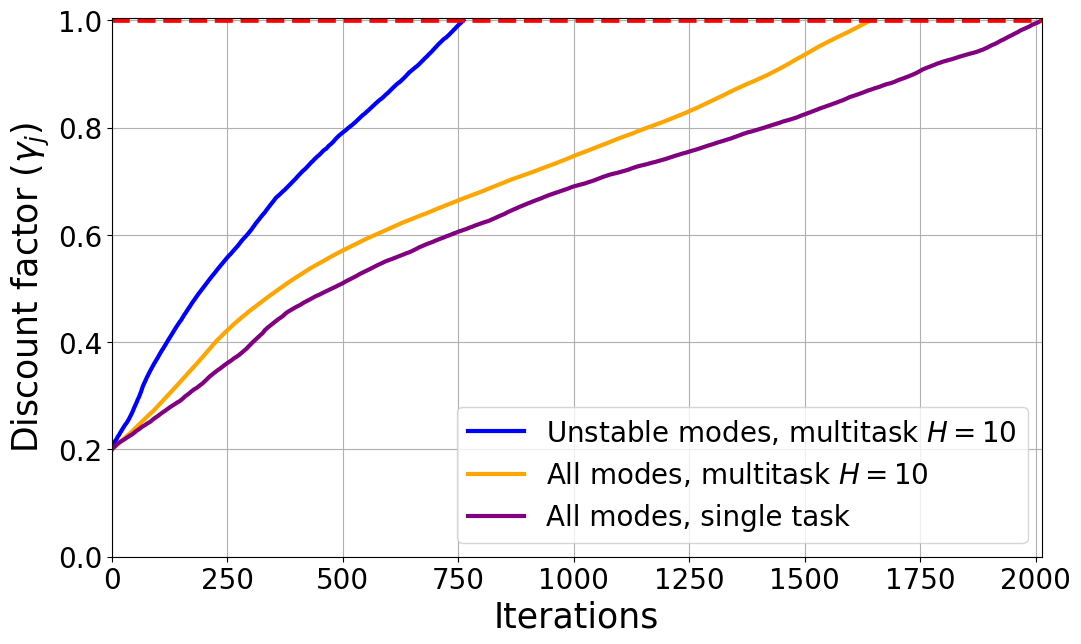

In [336]:
gamma_multitask_ld = []

for i in range(len(gammas_multitask_ld)):
    gamma_multitask_ld.append(gammas_multitask_ld[i][0])
    

plt.figure(figsize=(12,7))
plt.plot(gamma_multitask_ld, color='blue', label=r'Unstable modes, multitask $H = 10$', linewidth=3)
plt.plot(gamma_multitask_H25, color='orange', label=r'All modes, multitask $H = 10$', linewidth=3)
plt.plot(gamma_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(gamma_singletask)), np.ones(len(gamma_singletask)), linestyle='--', color='red', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylim(0, 1+0.5e-2)
plt.ylabel(r'Discount factor $(\gamma_j)$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()

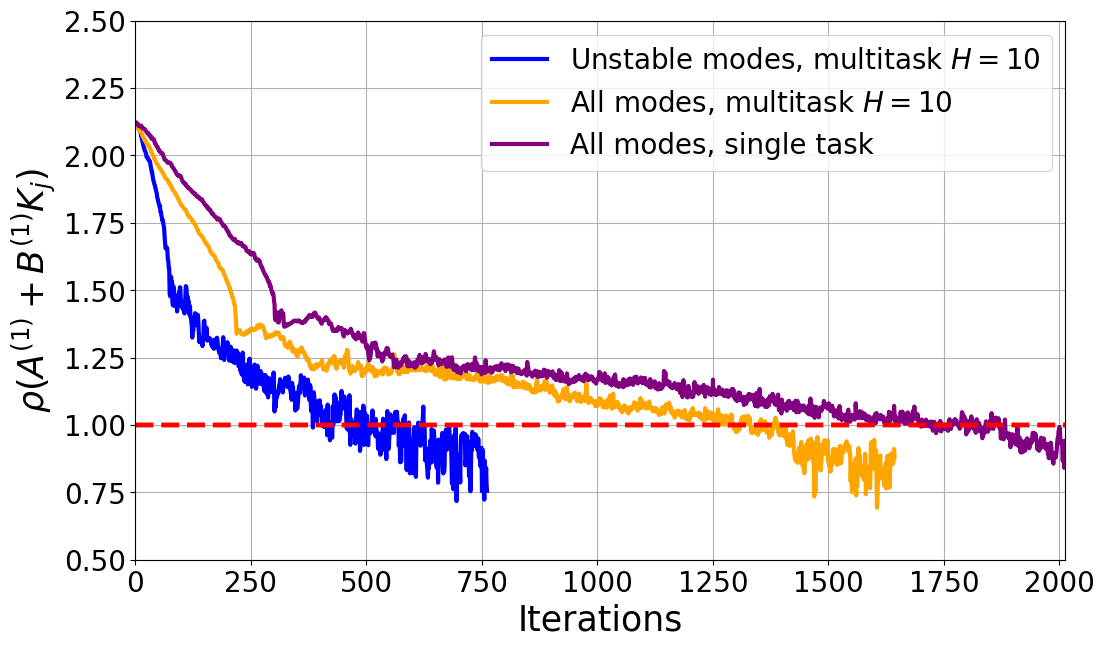

In [335]:
idx = 0

sr_multitask_ld = []

for i in range(len(srs_multitask_ld)):
    sr_multitask_ld.append(srs_multitask_ld[i][0])


plt.figure(figsize=(12,7))
plt.plot(sr_multitask_ld, color='blue', label=r'Unstable modes, multitask $H = 10$', linewidth=3)
plt.plot(sr_multitask_H25, color='orange', label=r'All modes, multitask $H = 10$', linewidth=3)
plt.plot(sr_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(sr_singletask)), np.ones(len(sr_singletask)), linestyle='--', color='red', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylim(0.5, 2.5)
plt.ylabel(r'$\rho(A^{(1)}+B^{(1)}K_{j})$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()